# DataCo EDA — demand forecasting sanity pass

Goal (kickoff plan, Week 1): confirm volumes, categories, date coverage,
and encoding quirks, and eyeball the weekly demand series before writing
`etl.py` / `aggregate.py`. Honest and short.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
df = pd.read_csv("../data/raw/DataCoSupplyChainDataset.csv", encoding="latin-1")
print(f"{len(df):,} rows x {df.shape[1]} columns")
print(f"memory: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

180,519 rows x 53 columns
memory: 135 MB


In [2]:
# the columns the pipeline will keep (per kickoff plan)
KEEP = [
    "order date (DateOrders)", "Category Name", "Order Item Quantity", "Sales",
    "Market", "Order Region", "Days for shipping (real)",
    "Days for shipment (scheduled)", "Delivery Status", "Late_delivery_risk",
]
missing = [c for c in KEEP if c not in df.columns]
assert not missing, f"expected columns missing: {missing}"
df[KEEP].head(3)

,order date (DateOrders),Category Name,Order Item Quantity,Sales,Market,Order Region,Days for shipping (real),Days for shipment (scheduled),Delivery Status,Late_delivery_risk
0,1/31/2018 22:56,Sporting Goods,1,327.75,Pacific Asia,Southeast Asia,3,4,Advance shipping,0
1,1/13/2018 12:27,Sporting Goods,1,327.75,Pacific Asia,South Asia,5,4,Late delivery,1
2,1/13/2018 12:06,Sporting Goods,1,327.75,Pacific Asia,South Asia,4,4,Shipping on time,0


In [3]:
# date coverage
dates = pd.to_datetime(df["order date (DateOrders)"], format="%m/%d/%Y %H:%M")
print("range:", dates.min(), "->", dates.max())
print("span:", (dates.max() - dates.min()).days, "days,",
      f"~{(dates.max() - dates.min()).days / 7:.0f} weeks")
print("null dates:", dates.isna().sum())

range: 2015-01-01 00:00:00 -> 2018-01-31 23:38:00
span: 1126 days, ~161 weeks
null dates: 0


In [4]:
# category volumes — which series are worth modeling?
vol = (df.groupby("Category Name")["Order Item Quantity"]
         .sum().sort_values(ascending=False))
print(f"{len(vol)} categories; top 10 hold "
      f"{vol.head(10).sum() / vol.sum():.0%} of all units")
vol.head(10)

50 categories; top 10 hold 89% of all units


Category Name
Cleats                  73734
Women's Apparel         62956
Indoor/Outdoor Games    57803
Cardio Equipment        37587
Shop By Sport           32726
Men's Footwear          22246
Fishing                 17325
Water Sports            15540
Camping & Hiking        13729
Electronics              9436
Name: Order Item Quantity, dtype: int64

In [5]:
# quirks worth knowing before ETL
print("duplicate full rows:", df.duplicated().sum())
print("negative/zero quantities:", (df["Order Item Quantity"] <= 0).sum())
print("null quantities:", df["Order Item Quantity"].isna().sum())
print("delivery status values:", df["Delivery Status"].unique().tolist())
print("late delivery rate:", f"{df['Late_delivery_risk'].mean():.1%}")
print("markets:", df["Market"].unique().tolist())

duplicate full rows: 0
negative/zero quantities: 0
null quantities: 0
delivery status values: ['Advance shipping', 'Late delivery', 'Shipping on time', 'Shipping canceled']
late delivery rate: 54.8%
markets: ['Pacific Asia', 'USCA', 'Africa', 'Europe', 'LATAM']


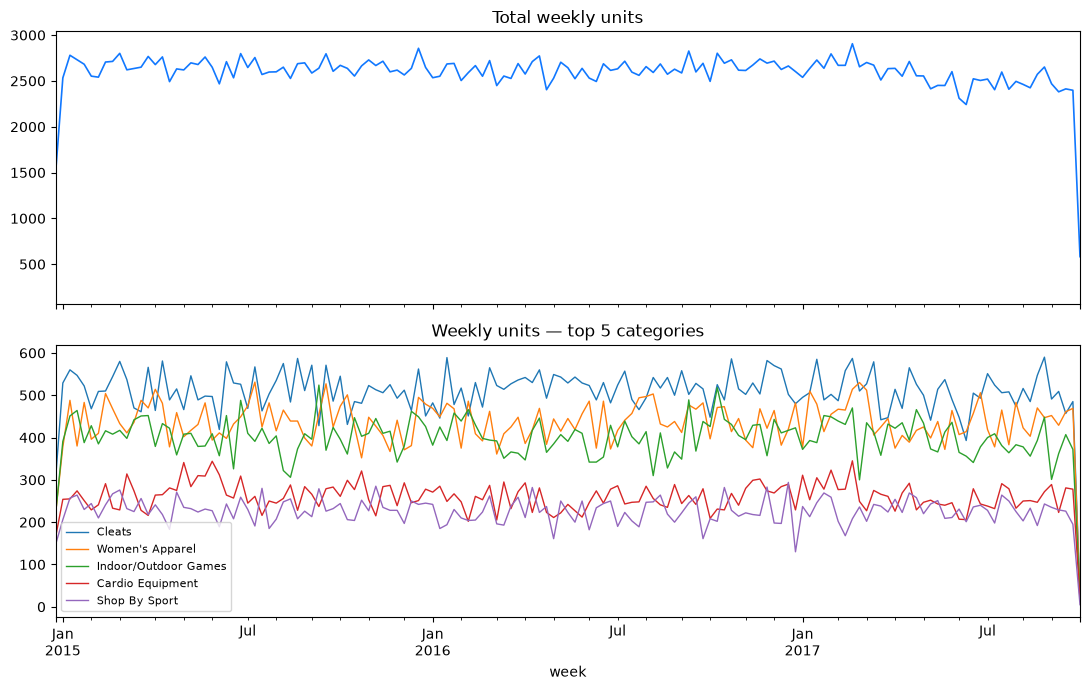

In [6]:
# weekly demand sanity plot — total + top 5 categories
wk = df.assign(week=dates.dt.to_period("W").dt.start_time)
top5 = vol.head(5).index
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

wk.groupby("week")["Order Item Quantity"].sum().plot(
    ax=axes[0], color="#1178ff", lw=1.2, title="Total weekly units")

for cat in top5:
    (wk[wk["Category Name"] == cat]
       .groupby("week")["Order Item Quantity"].sum()
       .plot(ax=axes[1], lw=1, label=cat))
axes[1].set_title("Weekly units — top 5 categories")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("../docs/screenshots/eda_weekly_series.png", dpi=110)
plt.show()

## Takeaways for `etl.py`

- **Shape confirmed:** 180,519 rows x 53 cols, exactly as the dataset card says. ~135 MB in memory — trim to the KEEP columns early.
- **Dates:** parse with `format="%m/%d/%Y %H:%M"`; coverage 2015-01-01 -> 2018-01-31 (~161 weeks). First and last calendar weeks are partial — **drop incomplete boundary weeks** during weekly aggregation or they will read as fake demand drops.
- **Clean beyond expectations:** 0 duplicate rows, 0 null/negative quantities, 0 null dates. ETL stays simple.
- **Categories:** 50 total, top 10 = 89% of units. Model the **top 8 by volume**, aggregate weekly.
- **Fulfillment story is rich:** 54.8% late-delivery rate, 4 delivery statuses, 5 markets — the 2-sigma late-rate anomaly layer has real signal to find.
- **`Shipping canceled` rows exist** — decide in ETL whether canceled orders count as demand (recommend: keep for demand, flag for fulfillment metrics).
